# Where should a Mobile Stroke Unit be based?

A **Mobile Stroke Unit (MSU)** is a specialized ambulance with an on-board CT
scanner and clinical staff, so stroke treatment can start before the patient
reaches a hospital. This notebook walks through the two optimization models
from our study on MSU placement in the Oslo region, on a **small synthetic
example** (the study data is not included):

1. **Without rendezvous** — a patient counts as covered if the MSU can drive
   to them within a time threshold (18 minutes in the study).
2. **With rendezvous** — a patient also counts as covered if a regular
   ambulance can pick them up and meet the MSU en route, which extends the
   MSU's effective reach.

Both are *Maximal Covering Location Problems*: choose base locations that
maximize the number of stroke patients reachable in time. See the
[README](README.md) for the full mathematical formulation, and the paper for
the study itself:

> Markhorst, B., Jagtenberg, C., Hov, M. R., van der Mei, R., & Larsen, K.
> (2025). Optimizing mobile stroke unit deployment: A strategic case study in
> the greater Oslo area. *European Stroke Journal*, 10(4), 1438–1444.
> [doi:10.1177/23969873251329862](https://doi.org/10.1177/23969873251329862)

The models are built with [Pyomo](https://www.pyomo.org), so any solver works;
here we use the open-source [HiGHS](https://highs.dev) solver
(`pip install -r requirements.txt` installs everything needed).

## 1. A synthetic region

We invent a small region: 20 towns scattered over a 60 × 60 km area. Each town
has a yearly number of strokes (the *demand*), and three towns host a regular
ambulance base. Travel times are straight-line distance at 70 km/h — in the
real study these were road-network travel times between postal codes.

In [1]:
import math
import random

random.seed(42)

# 20 towns on a 60 x 60 km grid, with strokes/year as demand.
towns = [f"T{k:02d}" for k in range(20)]
coords = {t: (random.uniform(0, 60), random.uniform(0, 60)) for t in towns}
demand = {t: random.randint(1, 30) for t in towns}

# Travel time in seconds between any two towns (straight line at 70 km/h).
SPEED_KMH = 70.0
travel_times = {
    (a, b): math.dist(coords[a], coords[b]) / SPEED_KMH * 3600
    for a in towns
    for b in towns
}

ambulance_bases = ["T03", "T11", "T17"]

print(f"{len(towns)} towns, {sum(demand.values())} strokes/year in total")

20 towns, 279 strokes/year in total


## 2. Model 1: placement without rendezvous

`build_msu_model` builds the classic covering model: place `n_msus` bases so
that the demand within the 18-minute threshold is maximized. Every town is a
candidate base location by default.

In [2]:
from msu_models import build_msu_model, compute_rendezvous_coverage, solve

model_plain = build_msu_model(
    demand,
    travel_times,
    time_threshold=18 * 60,  # 18 minutes, the value used in the study
    n_msus=1,
)
plain = solve(model_plain)  # uses HiGHS; pass solver="cbc", "glpk", "gurobi", ...

print(f"Best base:        {plain.chosen_locations[0]}")
print(f"Towns covered:    {len(plain.covered_points)} of {len(towns)}")
print(f"Patients covered: {plain.covered_demand:.0f} of {sum(demand.values())} per year")

Best base:        T19
Towns covered:    8 of 20
Patients covered: 100 of 279 per year


## 3. Model 2: placement with ambulance rendezvous

If a regular ambulance picks the patient up and drives towards the MSU while
the MSU drives towards them, the patient can be inside the MSU in time even
when the town is outside the 18-minute radius. Which town/base pairs gain
coverage this way is precomputed as binary indicators `beta[i, j]` from the
travel times and the ambulance base locations
(see `compute_rendezvous_coverage` for the exact condition); the optimization
model itself only changes by one extra term in the coverage constraint.

In [3]:
beta = compute_rendezvous_coverage(
    travel_times,
    ambulance_bases=ambulance_bases,
    demand_points=towns,
)

model_rv = build_msu_model(demand, travel_times, rendezvous_coverage=beta)
rendezvous = solve(model_rv)

print(f"Best base:        {rendezvous.chosen_locations[0]}")
print(f"Towns covered:    {len(rendezvous.covered_points)} of {len(towns)}")
print(f"Patients covered: {rendezvous.covered_demand:.0f} of {sum(demand.values())} per year")
print(f"\nRendezvous raises coverage from {plain.covered_demand:.0f} "
      f"to {rendezvous.covered_demand:.0f} patients per year.")

Best base:        T07
Towns covered:    18 of 20
Patients covered: 242 of 279 per year

Rendezvous raises coverage from 100 to 242 patients per year.


## 4. The two solutions on a map

Marker area is proportional to a town's demand. The dashed circle is the
18-minute direct-coverage radius around the chosen base — with rendezvous,
coverage clearly extends beyond it.

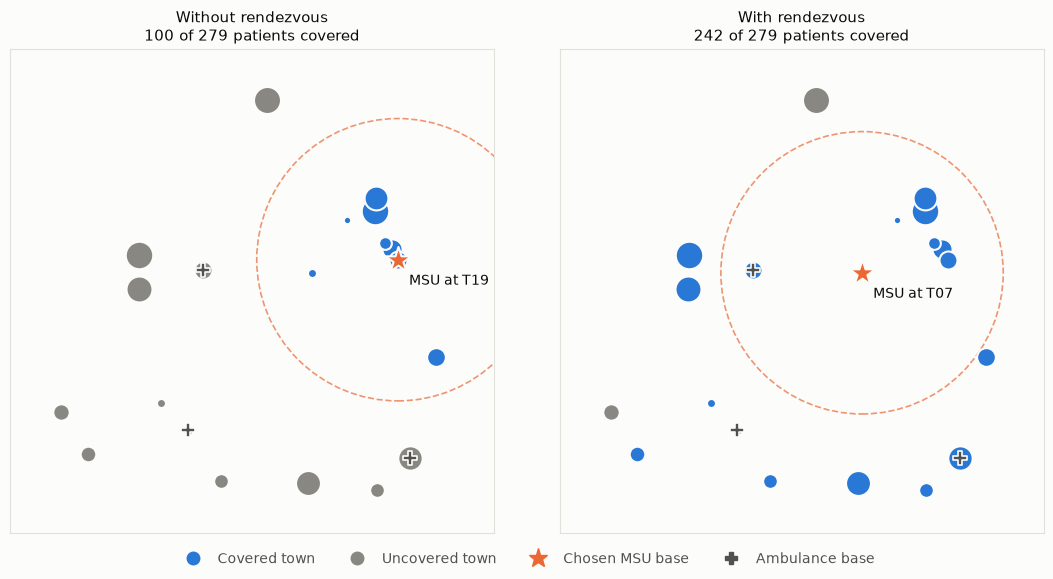

In [4]:
import matplotlib.pyplot as plt

SURFACE = "#fcfcfb"   # chart surface
COVERED = "#2a78d6"   # blue: covered towns
UNCOVERED = "#898781" # gray: uncovered towns
MSU = "#eb6834"       # orange: chosen MSU base
INK = "#0b0b0b"
INK_2 = "#52514e"

DIRECT_RADIUS_KM = SPEED_KMH * (18 / 60)  # 18 min at 70 km/h = 21 km


def plot_solution(ax, result, title):
    covered = set(result.covered_points)
    base = result.chosen_locations[0]

    for t in towns:
        x, y = coords[t]
        color = COVERED if t in covered else UNCOVERED
        ax.scatter(x, y, s=14 * demand[t], color=color, edgecolor=SURFACE,
                   linewidth=1.5, zorder=3)

    # Ambulance bases: shape carries identity, not only color.
    for a in ambulance_bases:
        ax.scatter(*coords[a], marker="P", s=90, color=INK_2,
                   edgecolor=SURFACE, linewidth=1.2, zorder=4)

    bx, by = coords[base]
    ax.scatter(bx, by, marker="*", s=380, color=MSU, edgecolor=SURFACE,
               linewidth=1.5, zorder=5)
    ax.annotate(f"MSU at {base}", (bx, by), xytext=(8, -18),
                textcoords="offset points", fontsize=10, color=INK)
    ax.add_patch(plt.Circle((bx, by), DIRECT_RADIUS_KM, fill=False,
                            edgecolor=MSU, linestyle="--", linewidth=1.2,
                            alpha=0.7, zorder=2))

    ax.set_title(f"{title}\n{result.covered_demand:.0f} of "
                 f"{sum(demand.values())} patients covered",
                 fontsize=11, color=INK)
    ax.set_facecolor(SURFACE)
    ax.set_aspect("equal")
    ax.set_xlim(-6, 66)
    ax.set_ylim(-6, 66)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#e1e0d9")


fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), facecolor=SURFACE)
plot_solution(axes[0], plain, "Without rendezvous")
plot_solution(axes[1], rendezvous, "With rendezvous")

handles = [
    plt.Line2D([], [], marker="o", ls="", color=COVERED, markersize=9,
               label="Covered town"),
    plt.Line2D([], [], marker="o", ls="", color=UNCOVERED, markersize=9,
               label="Uncovered town"),
    plt.Line2D([], [], marker="*", ls="", color=MSU, markersize=14,
               label="Chosen MSU base"),
    plt.Line2D([], [], marker="P", ls="", color=INK_2, markersize=9,
               label="Ambulance base"),
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
           labelcolor=INK_2)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 5. Scenario analysis

In the study we also asked "what if the MSU *must* be based at an existing
hospital or ambulance base?" — that is a `fixed_locations` argument — and how
much extra coverage additional MSUs buy (`n_msus`).

In [5]:
# Force the MSU to an existing ambulance base and measure the cost of doing so.
for base in ambulance_bases:
    fixed = solve(build_msu_model(demand, travel_times, fixed_locations=[base],
                                  rendezvous_coverage=beta))
    print(f"MSU fixed at ambulance base {base}: "
          f"{fixed.covered_demand:.0f} patients covered "
          f"(optimum was {rendezvous.covered_demand:.0f})")

# How much do extra MSUs help?
print()
for p in range(1, 4):
    more = solve(build_msu_model(demand, travel_times, n_msus=p,
                                 rendezvous_coverage=beta))
    print(f"{p} MSU(s) at {more.chosen_locations}: "
          f"{more.covered_demand:.0f} patients covered")

MSU fixed at ambulance base T03: 158 patients covered (optimum was 242)


MSU fixed at ambulance base T11: 168 patients covered (optimum was 242)


MSU fixed at ambulance base T17: 158 patients covered (optimum was 242)



1 MSU(s) at ['T07']: 242 patients covered


2 MSU(s) at ['T07', 'T16']: 269 patients covered


3 MSU(s) at ['T13', 'T16', 'T19']: 279 patients covered


## Using your own data and solver

To apply this to a real region you need three ingredients, in any units you
like as long as they are consistent:

- `demand`: a dict mapping each demand point (postal code, municipality, grid
  cell, ...) to its number of (suspected) strokes,
- `travel_times`: a dict mapping `(from, to)` pairs to travel times — ideally
  from a routing service rather than straight-line distance,
- `ambulance_bases`: the locations of regular ambulances (rendezvous model
  only).

Because the builders return plain Pyomo models, any solver Pyomo supports can
be used: `solve(model, solver="cbc")`, `solver="glpk"`, `solver="gurobi"`, and
so on.